<a href="https://colab.research.google.com/github/aakaash-12/ITA0610_ML-192412068/blob/main/Copy_of_ITA0610machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

# Create dataset
data = pd.DataFrame({
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
})

concepts = np.array(data.iloc[:, :-1])
target = np.array(data.iloc[:, -1])

def candidate_elimination(concepts, target):
    specific = concepts[0].copy()
    general = [['?' for _ in range(len(specific))] for _ in range(len(specific))]

    for i, h in enumerate(concepts):
        if target[i] == "Yes":
            for x in range(len(specific)):
                if h[x] != specific[x]:
                    specific[x] = '?'
                    general[x][x] = '?'
        else:
            for x in range(len(specific)):
                if h[x] != specific[x]:
                    general[x][x] = specific[x]
                else:
                    general[x][x] = '?'

    general = [g for g in general if g != ['?'] * len(specific)]
    return specific, general

s, g = candidate_elimination(concepts, target)

print("Specific Hypothesis:")
print(s)

print("\nGeneral Hypothesis:")
for hypothesis in g:
    print(hypothesis)



Specific Hypothesis:
['Sunny' 'Warm' '?' 'Strong' '?' '?']

General Hypothesis:
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Create dataset
data = pd.DataFrame({
    'Outlook':['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature':['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'PlayTennis':['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No']
})

print(data)

# Encode categorical values
encoder = LabelEncoder()
for col in data.columns:
    data[col] = encoder.fit_transform(data[col])

X = data.iloc[:, :-1]
Y = data.iloc[:, -1]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=1
)

model = DecisionTreeClassifier(criterion="entropy")
model.fit(X_train, Y_train)

pred = model.predict(X_test)

print("\nAccuracy:", accuracy_score(Y_test, pred))

# Example new sample: Outlook=Sunny, Temperature=Hot, Humidity=High, Wind=Weak
sample = [[2, 1, 0, 1]]
prediction = model.predict(sample)

print("Prediction:", prediction)


     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No

Accuracy: 0.4
Prediction: [0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

iris=load_iris()

X=iris.data
Y=iris.target

X_train,X_test,Y_train,Y_test=train_test_split(
X,Y,test_size=0.3,random_state=42)

scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

model=MLPClassifier(hidden_layer_sizes=(10,),
                    max_iter=1000,
                    random_state=1)

model.fit(X_train,Y_train)

pred=model.predict(X_test)

print("Accuracy =",accuracy_score(Y_test,pred))


Accuracy = 0.9777777777777777


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix,accuracy_score

iris=load_iris()

X=iris.data
Y=iris.target

X_train,X_test,Y_train,Y_test=train_test_split(
X,Y,test_size=0.3,random_state=42)

scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

classifier=KNeighborsClassifier(n_neighbors=3)

classifier.fit(X_train,Y_train)

pred=classifier.predict(X_test)

print("Confusion Matrix")

print(confusion_matrix(Y_test,pred))

print("\nAccuracy")

print(accuracy_score(Y_test,pred))



Confusion Matrix
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Accuracy
1.0


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score

# Load Iris dataset
iris = load_iris()

X = iris.data
Y = iris.target

# Split dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42)

# Train Naive Bayes model
model = GaussianNB()
model.fit(X_train, Y_train)

# Prediction
pred = model.predict(X_test)

# Results
print("Confusion Matrix:")
print(confusion_matrix(Y_test, pred))

print("\nAccuracy:")
print(accuracy_score(Y_test, pred))


Confusion Matrix:
[[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]

Accuracy:
0.9777777777777777


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

# Load Iris dataset
iris = load_iris()

X = iris.data
Y = iris.target

# Split dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Logistic Regression Model
model = LogisticRegression(max_iter=200)

model.fit(X_train, Y_train)

# Prediction
pred = model.predict(X_test)

# Results
print("Confusion Matrix:")
print(confusion_matrix(Y_test, pred))

print("\nAccuracy:")
print(accuracy_score(Y_test, pred))



Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Accuracy:
1.0


In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load Diabetes Dataset
diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Linear Regression Model
model = LinearRegression()

# Train the Model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Results
print("Coefficient:")
print(model.coef_)

print("\nIntercept:")
print(model.intercept_)

print("\nMean Squared Error:")
print(mean_squared_error(y_test, y_pred))

print("\nR2 Score:")
print(r2_score(y_test, y_pred))


Coefficient:
[  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]

Intercept:
151.34560453985995

Mean Squared Error:
2900.193628493482

R2 Score:
0.4526027629719195


    mpg  cylinders  displacement  horsepower  weight  acceleration  year  \
0  18.0          8         307.0         130    3504          12.0    70   
1  15.0          8         350.0         165    3693          11.5    70   
2  18.0          8         318.0         150    3436          11.0    70   
3  16.0          8         304.0         150    3433          12.0    70   
4  17.0          8         302.0         140    3449          10.5    70   

   origin                       name  
0       1  chevrolet chevelle malibu  
1       1          buick skylark 320  
2       1         plymouth satellite  
3       1              amc rebel sst  
4       1                ford torino  
Linear Regression
MSE: 22.153237123863413
R2 Score: 0.5659681822256185

Polynomial Regression
MSE: 18.416967796017616
R2 Score: 0.6391701147013347


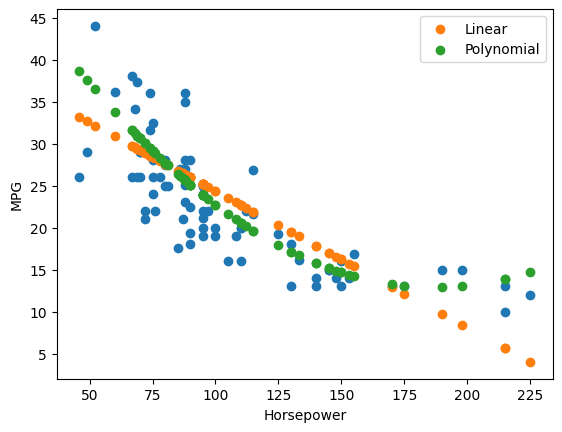

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# Load Auto MPG dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/Auto.csv"
data = pd.read_csv(url)

print(data.head())

# Remove missing values
data = data.replace('?', np.nan)
data = data.dropna()

# Convert columns
data['horsepower'] = pd.to_numeric(data['horsepower'])

X = data[['horsepower']]
y = data['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------------- LINEAR REGRESSION ----------------
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

# ---------------- POLYNOMIAL REGRESSION ----------------
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

poly_pred = poly_model.predict(X_test_poly)

# Results
print("Linear Regression")
print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2 Score:", r2_score(y_test, linear_pred))

print("\nPolynomial Regression")
print("MSE:", mean_squared_error(y_test, poly_pred))
print("R2 Score:", r2_score(y_test, poly_pred))

# Plot
plt.scatter(X_test, y_test)
plt.scatter(X_test, linear_pred, label="Linear")
plt.scatter(X_test, poly_pred, label="Polynomial")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.legend()
plt.show()


   Annual_Income  Annual_Spending
0          35795            58351
1          20860            66267
2          96820            53354
3          74886             7557
4          26265            43360

Clustered Data:
   Annual_Income  Annual_Spending  Cluster
0          35795            58351        0
1          20860            66267        0
2          96820            53354        2
3          74886             7557        1
4          26265            43360        0

Cluster Means:
         Annual_Income  Annual_Spending
Cluster                                
0         33619.197674     40804.500000
1         89098.192308     23804.326923
2         82343.790909     62603.172727


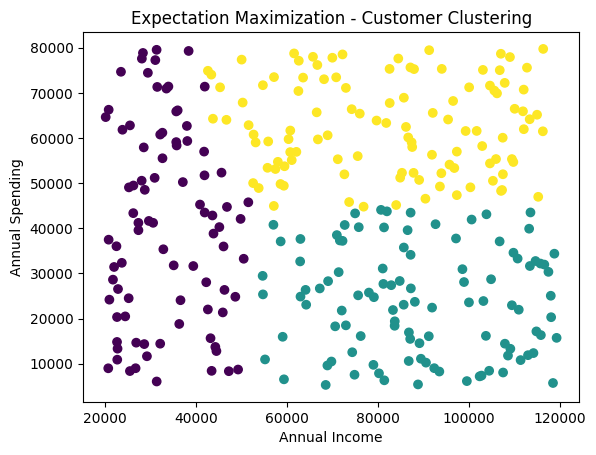

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

# Create unique customer dataset
np.random.seed(42)

customers = pd.DataFrame({
    "Annual_Income": np.random.randint(20000, 120000, 300),
    "Annual_Spending": np.random.randint(5000, 80000, 300)
})

print(customers.head())

# Scale data
scaler = StandardScaler()
X = scaler.fit_transform(customers)

# EM algorithm using Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

gmm.fit(X)

# Predict clusters
customers["Cluster"] = gmm.predict(X)

print("\nClustered Data:")
print(customers.head())

print("\nCluster Means:")
print(customers.groupby("Cluster").mean())

# Plot
plt.scatter(
    customers["Annual_Income"],
    customers["Annual_Spending"],
    c=customers["Cluster"]
)

plt.xlabel("Annual Income")
plt.ylabel("Annual Spending")
plt.title("Expectation Maximization - Customer Clustering")
plt.show()


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)

# Create dataset
n = 1000

data = pd.DataFrame({
    "Income": np.random.randint(20000, 150000, n),
    "Age": np.random.randint(21, 65, n),
    "Loan_Amount": np.random.randint(5000, 100000, n),
    "Credit_History": np.random.randint(0, 2, n),
    "Late_Payments": np.random.randint(0, 10, n),
    "Existing_Loans": np.random.randint(0, 5, n)
})

# Generate credit score class
data["Credit_Score"] = np.where(
    (data["Credit_History"] == 1) &
    (data["Late_Payments"] <= 2) &
    (data["Income"] > 40000),
    "Good",
    "Poor"
)

print(data.head())

# Features
X = data.drop("Credit_Score", axis=1)
y = data["Credit_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

prediction = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction))
print("\nClassification Report:")
print(classification_report(y_test, prediction))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediction))



   Income  Age  Loan_Amount  Credit_History  Late_Payments  Existing_Loans  \
0  141958   53        24982               1              3               4   
1   35795   40        81961               0              0               0   
2   20860   33         6980               0              5               4   
3  123694   48        53290               1              3               1   
4  148106   49        31431               1              4               4   

  Credit_Score  
0         Poor  
1         Poor  
2         Poor  
3         Poor  
4         Poor  
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        Good       1.00      1.00      1.00        26
        Poor       1.00      1.00      1.00       174

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200


Confusion Matrix:
[[ 26   0]
 [  0 174]]


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

# Load dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# KNN
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

prediction = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction))

print("\nClassification Report:")
print(classification_report(
    y_test,
    prediction,
    target_names=iris.target_names
))



Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# STEP 1: CREATE A UNIQUE CAR PRICE DATASET
# --------------------------------------------------

np.random.seed(42)

n = 500

data = pd.DataFrame({
    "Car_Age": np.random.randint(0, 15, n),
    "Mileage": np.random.randint(5000, 150000, n),
    "Engine_CC": np.random.randint(800, 3000, n),
    "Horsepower": np.random.randint(60, 250, n),
    "Owner_Count": np.random.randint(1, 5, n),
    "Fuel_Type": np.random.choice(
        ["Petrol", "Diesel", "Hybrid"],
        n
    ),
    "Transmission": np.random.choice(
        ["Manual", "Automatic"],
        n
    ),
    "Brand": np.random.choice(
        ["Toyota", "Honda", "Hyundai", "BMW", "Ford"],
        n
    )
})

# --------------------------------------------------
# STEP 2: GENERATE REALISTIC CAR PRICES
# --------------------------------------------------

data["Price"] = (
    1500000
    - data["Car_Age"] * 90000
    - data["Mileage"] * 5
    + data["Engine_CC"] * 500
    + data["Horsepower"] * 4000
    - data["Owner_Count"] * 70000
    + np.where(data["Fuel_Type"] == "Hybrid", 300000, 0)
    + np.where(data["Fuel_Type"] == "Diesel", 100000, 0)
    + np.where(data["Transmission"] == "Automatic", 200000, 0)
    + np.where(data["Brand"] == "BMW", 1200000, 0)
    + np.where(data["Brand"] == "Toyota", 300000, 0)
    + np.random.normal(0, 150000, n)
)

# Make sure prices are positive
data["Price"] = data["Price"].clip(lower=200000)

print("Dataset Shape:", data.shape)
print("\nFirst 5 Records:")
print(data.head())


Dataset Shape: (500, 9)

First 5 Records:
   Car_Age  Mileage  Engine_CC  Horsepower  Owner_Count Fuel_Type  \
0        6    34592       1701         105            3    Hybrid   
1        3    15647       1489         214            2    Hybrid   
2       12   144788       2839         172            2    Petrol   
3       14   115627        809          76            2    Hybrid   
4       10    75316       1060         163            4    Petrol   

  Transmission    Brand         Price  
0    Automatic    Honda  2.350747e+06  
1       Manual   Toyota  3.268924e+06  
2    Automatic   Toyota  2.331990e+06  
3    Automatic      BMW  2.007997e+06  
4       Manual  Hyundai  1.102708e+06  


In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

import numpy as np

# Load dataset
housing = fetch_california_housing()

X = housing.data
y = housing.target

print("Features:")
print(housing.feature_names)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

prediction = model.predict(X_test)

print("\nMSE:", mean_squared_error(y_test, prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_test, prediction)))
print("R2 Score:", r2_score(y_test, prediction))

# Sample prediction
print("\nActual:", y_test[:5])
print("Predicted:", prediction[:5])



Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

MSE: 0.2553684927247781
RMSE: 0.5053399773665033
R2 Score: 0.8051230593157366

Actual: [0.477   0.458   5.00001 2.186   2.78   ]
Predicted: [0.5095    0.74161   4.9232571 2.52961   2.27369  ]


In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
iris = load_iris()

X = iris.data
y = iris.target

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Naive Bayes
model = GaussianNB()

model.fit(X_train, y_train)

prediction = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction))

print("\nClassification Report:")
print(classification_report(
    y_test,
    prediction,
    target_names=iris.target_names
))


Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score

# Dataset
data = load_breast_cancer()

X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB()
}

results = []

for name, model in models.items():

    # Use scaled data
    model.fit(X_train_scaled, y_train)

    prediction = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, prediction)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    "Accuracy",
    ascending=False
))


             Algorithm  Accuracy
0  Logistic Regression  0.982456
4                  SVM  0.982456
1                  KNN  0.956140
3        Random Forest  0.956140
5          Naive Bayes  0.929825
2        Decision Tree  0.912281


Dataset Shape: (1000, 9)

First 5 Records:
   RAM_GB  Storage_GB  Battery_mAh  Camera_MP  Screen_Size  Refresh_Rate  5G  \
0       8         128         5041        110          6.3           144   1   
1       5         512         6110         75          6.3            60   1   
2      12          32         4192        136          6.4           144   0   
3       9          32         2605         99          5.5           144   1   
4       6          32         4181        198          6.6            60   0   

   Fast_Charging_W Price_Range  
0               33     Premium  
1               10   Mid-Range  
2               25    Flagship  
3               18     Premium  
4               18   Mid-Range  

Price Range Distribution:
Price_Range
Budget       250
Mid-Range    250
Premium      250
Flagship     250
Name: count, dtype: int64

========== MODEL PERFORMANCE ==========
Accuracy: 80.0 %

Classification Report:
              precision    recall  f1-score   support

      Bu

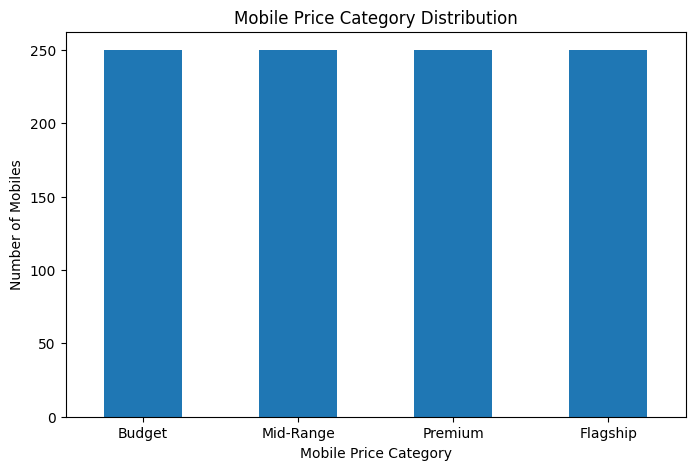

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
np.random.seed(42)

n = 1000

data = pd.DataFrame({
    "RAM_GB": np.random.randint(2, 13, n),
    "Storage_GB": np.random.choice(
        [32, 64, 128, 256, 512], n
    ),
    "Battery_mAh": np.random.randint(2500, 7000, n),
    "Camera_MP": np.random.randint(8, 200, n),
    "Screen_Size": np.round(
        np.random.uniform(5.0, 7.2, n), 1
    ),
    "Refresh_Rate": np.random.choice(
        [60, 90, 120, 144], n
    ),
    "5G": np.random.randint(0, 2, n),
    "Fast_Charging_W": np.random.choice(
        [10, 18, 25, 33, 45, 67, 80, 120], n
    )
})

score = (
    data["RAM_GB"] * 3
    + data["Storage_GB"] / 64
    + data["Battery_mAh"] / 1000
    + data["Camera_MP"] / 30
    + data["Refresh_Rate"] / 60
    + data["5G"] * 4
    + data["Fast_Charging_W"] / 20
)

# Divide phones into 4 price categories
data["Price_Range"] = pd.qcut(
    score,
    q=4,
    labels=[
        "Budget",
        "Mid-Range",
        "Premium",
        "Flagship"
    ]
)

print("Dataset Shape:", data.shape)

print("\nFirst 5 Records:")
print(data.head())

print("\nPrice Range Distribution:")
print(data["Price_Range"].value_counts())

X = data.drop("Price_Range", axis=1)
y = data["Price_Range"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = RandomForestClassifier(
    n_estimators=150,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\n========== MODEL PERFORMANCE ==========")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred
    )
)


comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head(15))
plt.figure(figsize=(8, 5))

data["Price_Range"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Mobile Price Category")
plt.ylabel("Number of Mobiles")
plt.title("Mobile Price Category Distribution")

plt.xticks(rotation=0)

plt.show()



In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, classification_report
# Load Iris
iris = load_iris()
X = iris.data
y = iris.target
# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Perceptron
model = Perceptron(
    max_iter=1000,
    eta0=0.1,
    random_state=42
)

model.fit(X_train, y_train)

prediction = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction))

print("\nClassification Report:")
print(classification_report(
    y_test,
    prediction,
    target_names=iris.target_names
))


Accuracy: 0.8666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virginica       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30



In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
np.random.seed(42)
n = 1200
data = pd.DataFrame({
    "Age": np.random.randint(21, 65, n),
    "Income": np.random.randint(20000, 150000, n),
    "Loan_Amount": np.random.randint(5000, 100000, n),
    "Credit_Score": np.random.randint(500, 850, n),
    "Employment_Years": np.random.randint(0, 30, n),
    "Existing_Loans": np.random.randint(0, 5, n),
    "Debt_Ratio": np.round(np.random.uniform(0.1, 0.8, n), 2)})
# Generate approval status
data["Loan_Status"] = np.where(
    (data["Credit_Score"] >= 650) &
    (data["Income"] >= 40000) &
    (data["Debt_Ratio"] <= 0.5) &
    (data["Existing_Loans"] <= 2),
    1,
    0
)
print(data.head())
# Features
X = data.drop("Loan_Status", axis=1)
y = data["Loan_Status"]

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
# Naive Bayes
model = GaussianNB()
model.fit(X_train, y_train)
prediction = model.predict(X_test)
print("\nAccuracy:", accuracy_score(y_test, prediction))
print("\nClassification Report:")
print(classification_report(y_test, prediction))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediction))



   Age  Income  Loan_Amount  Credit_Score  Employment_Years  Existing_Loans  \
0   59  143654        36348           682                22               4   
1   49   36032        69732           540                 4               1   
2   35   22198         6177           538                 3               3   
3   63   80500         9760           691                13               2   
4   28   73394        37779           766                 9               1   

   Debt_Ratio  Loan_Status  
0        0.75            0  
1        0.74            0  
2        0.67            0  
3        0.72            0  
4        0.24            1  

Accuracy: 0.95

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       201
           1       1.00      0.69      0.82        39

    accuracy                           0.95       240
   macro avg       0.97      0.85      0.89       240
weighted avg       0.95      0.95      

        Date         Sales
0 2018-01-01  10124.178538
1 2018-02-01  10545.433925
2 2018-03-01  11187.947538
3 2018-04-01  11620.757464
4 2018-05-01  11127.487060

MAE: 550.5593078935993
R2 Score: -0.5252601839277133


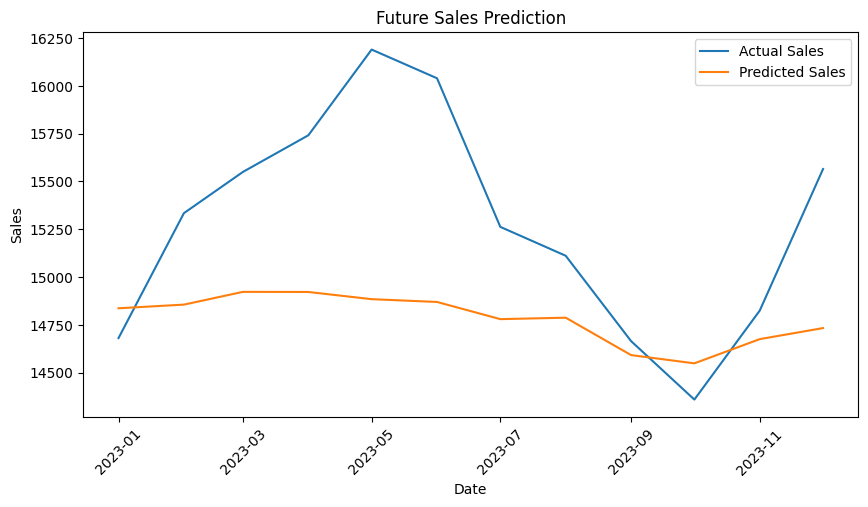


Predicted Future Sales: 14913.90989180787


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
np.random.seed(42)
# Create monthly sales dataset
dates = pd.date_range(
    start="2018-01-01",
    periods=72,
    freq="MS"
)
trend = np.arange(72) * 80
seasonality = 1000 * np.sin(
    2 * np.pi * np.arange(72) / 12
)
noise = np.random.normal(0, 250, 72)
sales = 10000 + trend + seasonality + noise
data = pd.DataFrame({
    "Date": dates,
    "Sales": sales
})
print(data.head())
# Create time features
data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Quarter"] = data["Date"].dt.quarter

# Lag features
data["Previous_Month_Sales"] = data["Sales"].shift(1)
data["Previous_Year_Sales"] = data["Sales"].shift(12)

data = data.dropna()

# Features
features = [
    "Year",
    "Month",
    "Quarter",
    "Previous_Month_Sales",
    "Previous_Year_Sales"
]
X = data[features]
y = data["Sales"]
# Time-based split
split = int(len(data) * 0.8)
X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]
# Random Forest
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
model.fit(X_train, y_train)
prediction = model.predict(X_test)

print("\nMAE:", mean_absolute_error(y_test, prediction))
print("R2 Score:", r2_score(y_test, prediction))

# Plot
plt.figure(figsize=(10, 5))

plt.plot(
    data["Date"].iloc[split:],
    y_test,
    label="Actual Sales"
)

plt.plot(
    data["Date"].iloc[split:],
    prediction,
    label="Predicted Sales"
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.xticks(rotation=45)
plt.show()

# Future prediction
last_row = data.iloc[-1]

future = pd.DataFrame({
    "Year": [last_row["Year"] + 1],
    "Month": [1],
    "Quarter": [1],
    "Previous_Month_Sales": [last_row["Sales"]],
    "Previous_Year_Sales": [last_row["Previous_Year_Sales"]]
})

future_prediction = model.predict(future)

print("\nPredicted Future Sales:", future_prediction[0])

